# Data preparation

This notebook shows the data every result in the project uses: all methods in `recommender.ipynb` and the frequent itemsets in `frequent_itemsets.ipynb` read the inventories through one shared definition, `recommender/data.py`. (`steam_cleaning.ipynb` is the group's first exploration of all three files; no result depends on it.)

**Source.** The Australian Steam data sets published by Julian McAuley's group at UC San Diego (https://cseweb.ucsd.edu/~jmcauley/datasets.html), cited as Kang & McAuley (2018), Wan & McAuley (2018) and Pathak, Gupta & McAuley (2017). We use two of the three files:

- `australian_users_items.json.gz`: each user's inventory, with the total playtime (`playtime_forever`, minutes) of every game. This is the input of every recommender.
- `steam_games.json.gz`: game metadata; only its user-voted tags are used, to describe the clusters in `recommender.ipynb`.

The reviews file is not used.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from recommender import data, evaluate

FIGURES = Path(data.DATA_DIR).parent / "figures"
FIGURES.mkdir(exist_ok=True)

## 1. Raw inventories

One row per (user, game) entry in the raw file.

In [2]:
raw = data.read_user_items()
print(f"{len(raw):,} rows, {raw['user_id'].nunique():,} users, {raw['item_id'].nunique():,} games")

5,153,209 rows, 70,912 users, 10,978 games


## 2. Duplicates

The raw file lists some users more than once, so some (user, game) entries repeat. A few repeats disagree on playtime; we keep the largest, since `playtime_forever` only grows over time.

In [3]:
per_pair = raw.groupby(["user_id", "item_id"])["playtime"]
n_rows = per_pair.size()
conflicting = (per_pair.nunique() > 1).sum()
user_items = data.deduplicate(raw)
print(f"{(n_rows > 1).sum():,} (user, game) entries appear more than once; {conflicting:,} of them disagree on playtime")
print(f"{len(raw) - len(user_items):,} duplicate rows removed, {len(user_items):,} entries left")

58,647 (user, game) entries appear more than once; 10 of them disagree on playtime
59,127 duplicate rows removed, 5,094,082 entries left


## 3. Played games only

A game counts for a user only if it was played (playtime above zero). Owned-but-unplayed games are left out: bundles and giveaways make ownership weak evidence of taste, and every method is trained and scored on plays.

In [4]:
played = user_items[user_items["playtime"] > 0]
print(f"{len(played):,} of {len(user_items):,} entries played ({len(played) / len(user_items):.1%})")

3,246,352 of 5,094,082 entries played (63.7%)


## 4. Enough players per game, enough games per user

Games need at least 50 players, so every method has enough users to learn about them; users need at least 5 played games, so some can be hidden for validation and testing. Removing games can push users below 5 and the other way round, so the two filters repeat until both hold (as in k-core filtering). The table shows the counts after each pass.

In [5]:
inter = data.build_interactions(user_items)
n_users, n_games = inter.playtime.shape
display(inter.filter_log)
print(f"{n_users:,} users x {n_games:,} games, {inter.playtime.nnz:,} played pairs: "
      f"{inter.playtime.nnz / (n_users * n_games):.2%} of the matrix is played")

,users,games,played pairs
step,,,
played entries,68403,10050,3246352
filter pass 1,59717,3720,3146315
filter pass 2,59716,3718,3146213
filter pass 3,59716,3718,3146213


59,716 users x 3,718 games, 3,146,213 played pairs: 1.42% of the matrix is played


## 5. Split per user

For every user, 20% of their played games are hidden as the **test** set; of the rest, another 20% are hidden as the **validation** set used for all tuning (`data.split_per_user`, same seeds as split 0 in `recommender.ipynb`). The filter in step 4 counts all plays, so after the split a game can have fewer than 50 training players.

In [6]:
train_full, test = data.split_per_user(inter.playtime, test_frac=0.2, seed=0)
train, valid = data.split_per_user(train_full, test_frac=0.2, seed=1)
print(f"train {train.nnz:,}  validation {valid.nnz:,}  test {test.nnz:,} played pairs")
print(f"training players per game: min {data.players_per_game(train).min()}")

train 2,013,843  validation 503,425  test 628,945 played pairs
training players per game: min 20


## 6. Popularity is concentrated

Games ranked by their number of players. The most-played 20% of games are what `recommender.ipynb` calls the head; the other 80% are the long tail.

head: 744 games (20%) hold 79.3% of played pairs; most-played game: 41,218 players; median game: 200 players


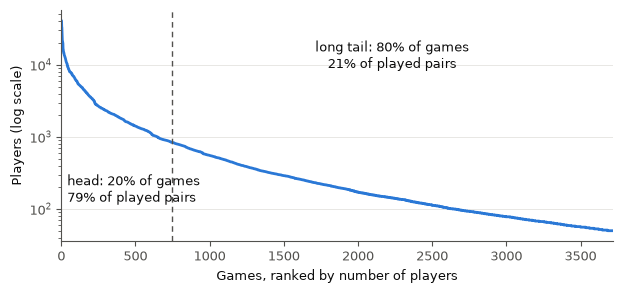

In [7]:
players = np.sort(data.players_per_game(inter.playtime))[::-1]
rank = np.arange(1, players.size + 1)
n_head = int(round(evaluate.HEAD_SHARE * players.size))
head_plays = players[:n_head].sum() / players.sum()
print(f"head: {n_head:,} games ({evaluate.HEAD_SHARE:.0%}) hold {head_plays:.1%} of played pairs; "
      f"most-played game: {players[0]:,} players; median game: {int(np.median(players))} players")

INK, MUTED, GRID, BLUE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED})
fig, ax = plt.subplots(figsize=(6.3, 3.0))
ax.plot(rank, players, color=BLUE, lw=2, solid_capstyle="round")
ax.axvline(n_head + 0.5, color=MUTED, lw=1, ls=(0, (4, 3)))
ax.set_yscale("log")
ax.set_xlim(0, players.size + 1)
ax.grid(axis="y", which="major", color=GRID, lw=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.text(40, players.min() * 2.2, f"head: {evaluate.HEAD_SHARE:.0%} of games\n{head_plays:.0%} of played pairs",
        ha="left", va="bottom", color=INK)
ax.text(n_head + (players.size - n_head) * 0.5, players[0] * 0.55,
        f"long tail: {1 - evaluate.HEAD_SHARE:.0%} of games\n{1 - head_plays:.0%} of played pairs",
        ha="center", va="top", color=INK)
ax.set_xlabel("Games, ranked by number of players")
ax.set_ylabel("Players (log scale)")
fig.tight_layout()
fig.savefig(FIGURES / "players_per_game.pdf")
fig.savefig(FIGURES / "players_per_game.png", dpi=200)
plt.show()